<a href="https://colab.research.google.com/github/parthaborgohain566/Prodigy-Infotech-Internship-Generative-AI-GA/blob/main/Task%2005%3A%20Neural%20%20%20Style%20Transfer/%20Neural_Style_Transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Neural Style Transfer

Neural Style Transfer (NST) is an optimization technique used to transform the style of one image (the 'style image') onto another image (the 'content image') while preserving the content of the content image. This technique was introduced by Gatys et al. in 2015.

The core idea involves using a pre-trained Convolutional Neural Network (CNN), like VGG19, to extract content and style features from the images. The process then optimizes a new 'generated' image to minimize a combined loss function that accounts for both content similarity to the content image and style similarity to the style image.

### Key Components:
1.  **Content Image**: The image from which we want to extract the structural content.
2.  **Style Image**: The image from which we want to extract the artistic style.
3.  **Generated Image**: The output image, initially noise or the content image, which is optimized to blend the content and style.
4.  **Feature Extractor (CNN)**: Typically a pre-trained VGG-19 network, used to extract features at different layers.
5.  **Content Loss**: Measures the difference in content representations between the generated image and the content image. It's usually a Mean Squared Error (MSE) loss on the feature maps of a higher-level layer.
6.  **Style Loss**: Measures the difference in style representations (Gram matrices of feature maps) between the generated image and the style image. This is calculated across multiple layers to capture multi-scale style features.
7.  **Total Loss**: A weighted sum of content loss and style loss, which is minimized using an optimization algorithm (e.g., L-BFGS or Adam).

### Setup and Imports

First, we need to install and import the necessary libraries. We'll primarily use TensorFlow and Keras for building and training the model, and Matplotlib for visualization.

In [ ]:
import os
import tensorflow as tf
import IPython.display as display

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import numpy as np
import PIL.Image

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


### Image Loading and Preprocessing

We'll define functions to:
1.  **Load an image**: Convert it to a TensorFlow tensor.
2.  **Preprocess the image**: Resize it to a maximum dimension while maintaining the aspect ratio, and then convert it to a suitable data type.
3.  **Display the image**: For visualization purposes.

In [ ]:
def load_img(path_to_img):
  max_dim = 512
  img = tf.io.read_file(path_to_img)
  img = tf.image.decode_image(img, channels=3)
  img = tf.image.convert_image_dtype(img, tf.float32)

  shape = tf.cast(tf.shape(img)[:-1], tf.float32)
  long_dim = max(shape)
  scale = max_dim / long_dim

  new_shape = tf.cast(shape * scale, tf.int32)

  img = tf.image.resize(img, new_shape)
  img = img[tf.newaxis, :]
  return img

def imshow(image, title=None):
  if len(image.shape) > 3:
    image = tf.squeeze(image, axis=0)

  plt.imshow(image)
  if title:
    plt.title(title)
  plt.show()

print("Image loading and display helper functions defined.")

Image loading and display helper functions defined.


### Content and Style Images

Now, let's load our content and style images. For demonstration purposes, we'll use a couple of images readily available or that can be downloaded. You can replace these paths with your own content and style images.

First, let's define the paths and then load and display them using our `load_img` and `imshow` functions.

### Uploading Your Own Images (Alternative)

Since we're encountering persistent issues with direct URL downloads, it's often more reliable to upload your own content and style images directly to your Colab environment. Follow these steps:

1.  **Click the 'Files' icon** on the left sidebar of your Colab notebook (it looks like a folder).
2.  **Click the 'Upload' icon** (it looks like a page with an arrow pointing up) to upload your desired content and style images from your local machine.
3.  Once uploaded, they will appear in the `/content/` directory.

After uploading, update the `content_path` and `style_path` variables below to point to the filenames of your uploaded images. For demonstration, I will use placeholder names that you should replace.

Content Image:


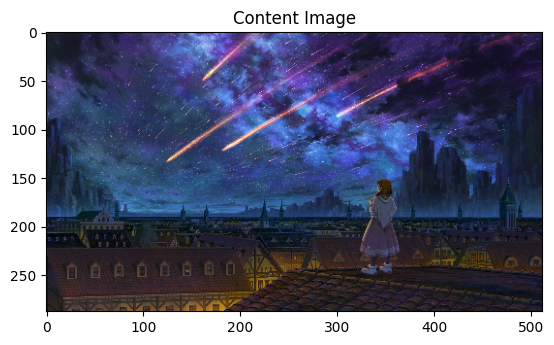

Style Image:


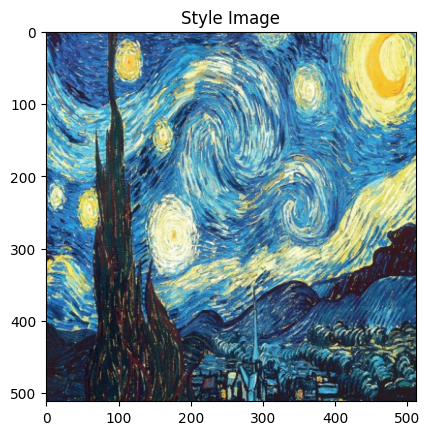

Content image shape: (1, 288, 512, 3)
Style image shape: (1, 512, 512, 3)


In [ ]:
# After uploading your images, replace 'my_content_image.jpg' and 'my_style_image.jpg'
# with the actual filenames of your uploaded images.

# Example: If you uploaded 'dog.jpg' and 'starry_night.jpg'
# content_path = 'dog.jpg'
# style_path = 'starry_night.jpg'

# Placeholder paths for demonstration. PLEASE UPDATE THESE WITH YOUR UPLOADED FILENAMES.
content_path = '/content/anime-version.jpg' # <--- REPLACE THIS
style_path = '/content/van2.jpg'     # <--- REPLACE THIS


# Verify that the files exist before attempting to load them
if not os.path.exists(content_path):
    raise FileNotFoundError(f"Content image not found at '{content_path}'. Please upload your content image and update the path.")
if not os.path.exists(style_path):
    raise FileNotFoundError(f"Style image not found at '{style_path}'. Please upload your style image and update the path.")

content_image = load_img(content_path)
style_image = load_img(style_path)

print("Content Image:")
imshow(content_image, 'Content Image')
print("Style Image:")
imshow(style_image, 'Style Image')

print("Content image shape:", content_image.shape)
print("Style image shape:", style_image.shape)

### Build the Model

We'll use a pre-trained VGG19 model and modify it to extract intermediate layer outputs. These intermediate outputs are crucial for calculating content and style losses.

In [ ]:
import tensorflow_hub as hub
import tensorflow_datasets as tfds

# Load the VGG19 model, pre-trained on ImageNet data
vgg = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
vgg.trainable = False

# Define the layers from which to extract content and style features
content_layers = ['block5_conv2']

style_layers = [
    'block1_conv1',
    'block2_conv1',
    'block3_conv1',
    'block4_conv1',
    'block5_conv1'
]

# Get the outputs of the selected layers
outputs = [vgg.get_layer(name).output for name in (style_layers + content_layers)]

# Create a Keras model that takes an image as input and outputs the content and style layer activations
model = tf.keras.Model([vgg.input], outputs)

print("VGG19 model loaded and configured for feature extraction.")
print("Content layer:", content_layers)
print("Style layers:", style_layers)

ERROR:absl:Detected incompatible Protobuf Gencode/Runtime versions when loading tensorflow_metadata/proto/v0/anomalies.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/__init__.py", line 79, in <module>
    from tensorflow_datasets import rlds  # pylint: disable=g-bad-import-order
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/rlds/__init__.py", line 21, in <module>
    from tensorflow_datasets.rlds import envlogger_reader
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/rlds/envlogger_reader.py", line 21, in <module>
    from tensorflow_datasets.core.utils.lazy_imports_utils import tree
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/co

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG19 model loaded and configured for feature extraction.
Content layer: ['block5_conv2']
Style layers: ['block1_conv1', 'block2_conv1', 'block3_conv1', 'block4_conv1', 'block5_conv1']


### Content and Style Loss Functions

To perform neural style transfer, we need to minimize two types of loss:

1.  **Content Loss**: Measures how much the generated image's content features differ from the content image's features.
2.  **Style Loss**: Measures how much the generated image's style features (represented by Gram matrices) differ from the style image's features.

We'll define helper functions for these, and then a `StyleContentModel` class that wraps the VGG19 model to return the content and style feature maps.

In [ ]:
def content_loss(base_content, target_content):
  return tf.reduce_mean(tf.square(base_content - target_content))

def gram_matrix(input_tensor):
  result = tf.linalg.einsum('bijc,bijd->bcd', input_tensor, input_tensor)
  input_shape = tf.shape(input_tensor)
  num_locations = tf.cast(input_shape[1]*input_shape[2], tf.float32)
  return result/(num_locations)

def style_loss(base_style, target_style):
  gm_base = gram_matrix(base_style)
  gm_target = gram_matrix(target_style)
  return tf.reduce_mean(tf.square(gm_base - gm_target))

print("Content and style loss functions defined.")

Content and style loss functions defined.


In [ ]:
class StyleContentModel(tf.keras.models.Model):
  def __init__(self, style_layers, content_layers):
    super(StyleContentModel, self).__init__()
    self.vgg =  tf.keras.applications.VGG19(include_top=False, weights='imagenet')
    self.vgg.trainable = False
    self.style_layers = style_layers
    self.content_layers = content_layers
    self.num_style_layers = len(style_layers)
    self.vgg_layers = [self.vgg.get_layer(name).output for name in style_layers + content_layers]
    self.extractor = tf.keras.Model(inputs=self.vgg.input, outputs=self.vgg_layers)

  def call(self, inputs):
    # Expects float input in [0,1]
    inputs = inputs*255.0
    preprocessed_input = tf.keras.applications.vgg19.preprocess_input(inputs)
    outputs = self.extractor(preprocessed_input)
    style_outputs, content_outputs = (outputs[:self.num_style_layers],
                                      outputs[self.num_style_layers:])

    # Removed the gram_matrix application from here
    # style_outputs = [gram_matrix(style_output) for style_output in style_outputs]

    return {'content': content_outputs,
            'style': style_outputs}

### Set up Content and Style Targets

Now we will instantiate the `StyleContentModel` using the `style_layers` and `content_layers` we defined earlier. Then, we will extract the target style and content features from our `style_image` and `content_image` respectively. These will be used to calculate the loss during optimization.

In [ ]:
# Create an instance of the StyleContentModel
extractor = StyleContentModel(style_layers, content_layers)

# Get target features for the style image
style_targets = extractor(style_image)['style']

# Get target features for the content image
content_targets = extractor(content_image)['content']

print("Extractor model initialized.")
print("Style targets extracted.")
print("Content targets extracted.")

Extractor model initialized.
Style targets extracted.
Content targets extracted.


### Run Gradient Descent

With our model and loss functions defined, we can now set up the optimization process:

1.  **Initialize the generated image**: We'll start with a copy of the content image as our initial generated image.
2.  **Define the optimizer**: We'll use the Adam optimizer.
3.  **Set up weights**: We'll define weights for the style and content losses.
4.  **Define the training step**: This will be a `tf.function` to compile the training step for faster execution.
5.  **Run the optimization loop**: We'll iterate for a number of epochs and steps, applying the gradients and updating the generated image.

In [ ]:
# Initialize the generated image with the content image
image = tf.Variable(content_image)

# Define the optimizer
optimizer = tf.optimizers.Adam(learning_rate=0.02, beta_1=0.99, epsilon=1e-1)

# Define the weights for style and content loss
style_weight=1e-2
content_weight=1e4
total_variation_weight=30 # To regularize the image and reduce high-frequency artifacts

print("Generated image initialized, optimizer and weights set.")

Generated image initialized, optimizer and weights set.


In [ ]:
@tf.function()
def train_step(image):
  with tf.GradientTape() as tape:
    model_outputs = extractor(image)
    style_outputs = model_outputs['style']
    content_outputs = model_outputs['content']

    # Calculate style loss
    s_loss = tf.add_n([style_loss(style_output, target) for style_output, target in zip(style_outputs, style_targets)])
    s_loss *= style_weight / len(style_layers)

    # Calculate content loss
    c_loss = tf.add_n([content_loss(content_output, target) for content_output, target in zip(content_outputs, content_targets)])
    c_loss *= content_weight / len(content_layers)

    # Calculate total variation loss
    tv_loss = tf.image.total_variation(image)
    tv_loss *= total_variation_weight

    total_loss = s_loss + c_loss + tv_loss

  grad = tape.gradient(total_loss, image)
  optimizer.apply_gradients([(grad, image)])
  image.assign(tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0))

  return total_loss, s_loss, c_loss, tv_loss

print("Training step function defined.")

Training step function defined.


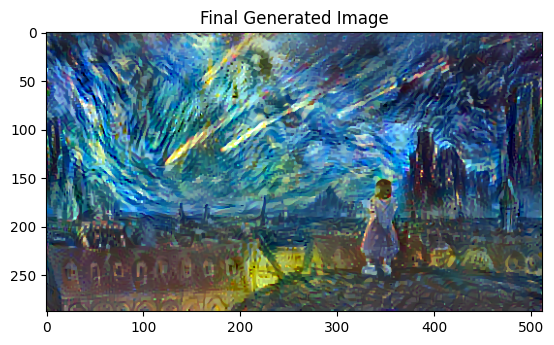

Total time: 57.69 seconds
Generated image saved as final_generated_image.png
Neural Style Transfer complete!


In [ ]:
import time

# For displaying intermediate images
def clip_0_1(image):
  return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)

epochs = 10
steps_per_epoch = 100

start_time = time.time()

for epoch in range(epochs):
  for step in range(steps_per_epoch):
    total_loss, s_loss, c_loss, tv_loss = train_step(image)

  # Display intermediate image and losses every epoch
  display.clear_output(wait=True)
  # Explicitly convert total_loss to a Python float before formatting
  imshow(image.read_value(), f"Epoch {epoch+1}/{epochs} | Total Loss: {total_loss.numpy().item():.2f}")
  print(f"Epoch {epoch+1}/{epochs} ")
  print(f"  Total Loss: {total_loss.numpy().item():.4f}, Style Loss: {s_loss.numpy().item():.4f}, Content Loss: {c_loss.numpy().item():.4f}, TV Loss: {tv_loss.numpy().item():.4f}")

end_time = time.time()
display.clear_output(wait=True)
imshow(image.read_value(), 'Final Generated Image')
print(f"Total time: {end_time - start_time:.2f} seconds")
print(f"Generated image saved as final_generated_image.png")

# Save the final image
final_image_path = 'final_generated_image.png'
tf.keras.utils.save_img(final_image_path, image[0])

print("Neural Style Transfer complete!")